# 02 — asof 차분 디코딩 · 라벨 레짐 검증 · 오염 제거

`asof_*` 는 **누적 비율**이고 `asof_pitcher_n` 은 **누적 개수**이므로,
같은 투수의 연속한 두 행을 차분하면 각 투구의 세부 결과가 복원된다.

$$M_k = \text{rate}_k \times k, \qquad
\mathbb{1}[\text{pitch }k] = M_{k+1} - M_k$$

이 노트북이 답하는 것:

1. **디코딩 정합성** — `success_rate` 차분이 `control_success` 와 일치하는가
2. **실패 3분해** — middle / reverse / far_off 복원
3. **라벨 레짐 단절** — F의 reverse 성분이 2022 이전에 ≈0 인가
4. **오염 제거** — R 전용 누적률로 재구성하면 팀13의 +0.035 편향이 사라지는가
5. **파생 피처** — `season_to_date_pitches` 생성 및 추론용 lookup 저장

노트북 01 을 먼저 돌려 `train` 이 메모리에 있어야 한다.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 60)

DATA_DIR = "/content/drive/MyDrive/lgaimers_9/data"
ART_DIR = "/content/drive/MyDrive/lgaimers_9/artifacts"          # 추론 때 model/ 로 옮길 산출물
os.makedirs(ART_DIR, exist_ok=True)

TARGET = "control_success"

if "train" not in dir():
    train = pd.read_csv(os.path.join(DATA_DIR, "train.csv"), encoding="utf-8-sig")
print(train.shape)

(1475092, 49)


## 0. 디코더

`ok` 는 "바로 다음 행이 같은 투수의 n+1 번째 투구"인 경우만 True.
train 은 2019–2024 연속이므로 각 투수의 **마지막 1구**만 디코딩 불가 (총 792행).

부동소수점 검증: `rate × n` 이 정수에서 얼마나 벗어나는지 먼저 본다.
`1e-6` 수준이면 반올림해도 안전하다.

In [3]:
def decode_series(df, rate_col, n_col, group_col):
    # 반환: (per-pitch 지표, 누적 개수, 유효 마스크, 정수 이탈량)
    n = df[n_col].to_numpy(dtype=np.float64)
    rate = df[rate_col].to_numpy(dtype=np.float64)
    cnt = np.where(n == 0, 0.0, rate * n)          # n=0 이면 rate 결측 -> 개수 0

    g = df[group_col].to_numpy()
    same = np.zeros(len(df), dtype=bool)
    same[:-1] = g[1:] == g[:-1]

    nxt_cnt = np.full(len(df), np.nan); nxt_cnt[:-1] = cnt[1:]
    nxt_n = np.full(len(df), np.nan);   nxt_n[:-1] = n[1:]

    ok = same & (nxt_n == n + 1)
    raw = np.where(ok, nxt_cnt - cnt, np.nan)

    dev = np.nanmax(np.abs(cnt[np.isfinite(cnt)] - np.round(cnt[np.isfinite(cnt)])))
    return raw, cnt, ok, dev


# 투수 시간축으로 정렬 (row_id 연대순 == asof_n 순, 노트북 01에서 확인)
P = train.sort_values(["pitcher_id", "asof_pitcher_n"], kind="mergesort").reset_index(drop=True)
print(f"정렬 완료: {len(P):,} 행")

정렬 완료: 1,475,092 행


In [4]:
PITCHER_RATES = {
    "success":  "asof_pitcher_success_rate",
    "reverse":  "asof_pitcher_reverse_rate",
    "middle":   "asof_pitcher_middle_rate",
    "ball":     "asof_pitcher_ball_rate",
    "strike":   "asof_pitcher_strike_rate",
}

dec = {}
print(f"{'성분':10s} {'정수이탈(max)':>16s} {'raw 이탈(max)':>16s} {'유효행':>12s}")
for name, col in PITCHER_RATES.items():
    raw, cnt, ok, dev = decode_series(P, col, "asof_pitcher_n", "pitcher_id")
    raw_dev = np.nanmax(np.abs(raw - np.round(raw)))
    dec[name] = np.where(ok, np.round(raw), np.nan)
    print(f"{name:10s} {dev:16.3e} {raw_dev:16.3e} {int(ok.sum()):12,}")

OK = np.isfinite(dec["success"])
print(f"\n디코딩 유효 행: {OK.sum():,} / {len(P):,}  (손실 {len(P)-OK.sum():,} = 투수 수)")

성분                정수이탈(max)      raw 이탈(max)          유효행
success           7.588e-03        1.462e-02    1,474,300
reverse           7.642e-03        1.524e-02    1,474,300
middle            7.650e-03        1.491e-02    1,474,300
ball              7.621e-03        1.474e-02    1,474,300
strike            7.600e-03        1.503e-02    1,474,300

디코딩 유효 행: 1,474,300 / 1,475,092  (손실 792 = 투수 수)


## 1. 검증 — `success` 차분 == `control_success`

일치해야 디코딩 전체가 옳다. 불일치가 있으면 정렬 키나 정밀도를 의심한다.

In [5]:
y = P[TARGET].to_numpy(dtype=np.float64)
mism = (dec["success"][OK] != y[OK])
print(f"불일치: {mism.sum():,} / {OK.sum():,}  ({mism.mean()*100:.6f}%)")

# 복원된 지표가 전부 {0,1} 인지
for name, v in dec.items():
    u = np.unique(v[np.isfinite(v)])
    print(f"  {name:10s} 값 집합: {u[:6]}{' ...' if len(u) > 6 else ''}")

assert mism.sum() == 0, "디코딩 불일치 — 정렬/정밀도 점검 필요"
print("\n✅ 디코딩 정합성 확인")

불일치: 0 / 1,474,300  (0.000000%)
  success    값 집합: [-0.  1.]
  reverse    값 집합: [-0.  1.]
  middle     값 집합: [0. 1.]
  ball       값 집합: [0. 1.]
  strike     값 집합: [-0.  1.]

✅ 디코딩 정합성 확인


## 2. 실패 3분해

대회 정의상 제구 실패 = (가운데) ∪ (크게 벗어남) ∪ (요구 반대).
middle · reverse 는 직접 복원되므로 나머지는 잔차로 얻는다.

$$\text{far\_off} = (1-\text{success}) \wedge \neg\text{middle} \wedge \neg\text{reverse}$$

먼저 **middle=1 또는 reverse=1 이면 반드시 success=0** 인지 확인한다.
이게 깨지면 합집합 정의 자체가 틀린 것이다.

In [6]:
D = pd.DataFrame({k: v for k, v in dec.items()}, index=P.index)
D["row_id"] = P["row_id"].values
D["pitcher_id"] = P["pitcher_id"].values
D["season"] = P["season"].values
D["game_type"] = P["game_type"].values
D["asof_pitcher_n"] = P["asof_pitcher_n"].values
D = D[OK].copy()

# 정의 정합성
print("middle=1 인데 success=1 :", int(((D["middle"] == 1) & (D["success"] == 1)).sum()))
print("reverse=1 인데 success=1:", int(((D["reverse"] == 1) & (D["success"] == 1)).sum()))
print("middle=1 & reverse=1    :", int(((D["middle"] == 1) & (D["reverse"] == 1)).sum()))

D["far_off"] = ((D["success"] == 0) & (D["middle"] == 0) & (D["reverse"] == 0)).astype(int)
D["inplay"] = (1 - D["ball"] - D["strike"]).astype(int)   # 볼도 스트라이크도 아님

print("\n=== 성분 비율 (전체) ===")
print(D[["success", "middle", "reverse", "far_off", "ball", "strike", "inplay"]]
      .mean().round(5).to_string())
print("\n실패 성분 합 vs 실패율:",
      round(D[["middle", "reverse", "far_off"]].sum(axis=1).mean(), 6),
      "vs", round(1 - D["success"].mean(), 6))

middle=1 인데 success=1 : 0
reverse=1 인데 success=1: 0
middle=1 & reverse=1    : 50266

=== 성분 비율 (전체) ===
success    0.52373
middle     0.14961
reverse    0.22904
far_off    0.13172
ball       0.36958
strike     0.44334
inplay     0.18709

실패 성분 합 vs 실패율: 0.510362 vs 0.476267


## 3. 라벨 레짐 단절 검증

가설: 2022 이전 F 에서는 **포수 요구 방향이 기록되지 않아 reverse 성분이 ≈0**,
그래서 성공률이 부풀려졌다. 2023 부터 기록이 시작되며 R 수준으로 수렴.

시즌 × game_type 으로 각 성분을 찍으면 바로 판별된다.

In [7]:
comp = (D.groupby(["game_type", "season"])[["success", "middle", "reverse", "far_off"]]
          .mean().round(4))
print(comp.to_string())

print("\n=== reverse 성분만 pivot ===")
rev = D.pivot_table(index="season", columns="game_type", values="reverse", aggfunc="mean").round(5)
print(rev)
print("\nF/R reverse 비율:")
print((rev["F"] / rev["R"]).round(4))

                  success  middle  reverse  far_off
game_type season                                   
F         2019     0.6889  0.0834   0.1249   0.1084
          2020     0.5877  0.1846   0.1512   0.0896
          2021     0.7035  0.0894   0.0917   0.1193
          2022     0.7086  0.1289   0.0482   0.1148
          2023     0.4728  0.1157   0.2997   0.1444
          2024     0.4590  0.1598   0.2879   0.1347
R         2019     0.5495  0.1301   0.1884   0.1628
          2020     0.5269  0.1443   0.2153   0.1473
          2021     0.5128  0.1501   0.2623   0.1195
          2022     0.5037  0.1524   0.2586   0.1269
          2023     0.5031  0.1577   0.2507   0.1229
          2024     0.4897  0.1785   0.2427   0.1214

=== reverse 성분만 pivot ===
game_type        F        R
season                     
2019       0.12492  0.18836
2020       0.15119  0.21530
2021       0.09175  0.26232
2022       0.04824  0.25859
2023       0.29973  0.25072
2024       0.28789  0.24270

F/R reverse 비율:
seas

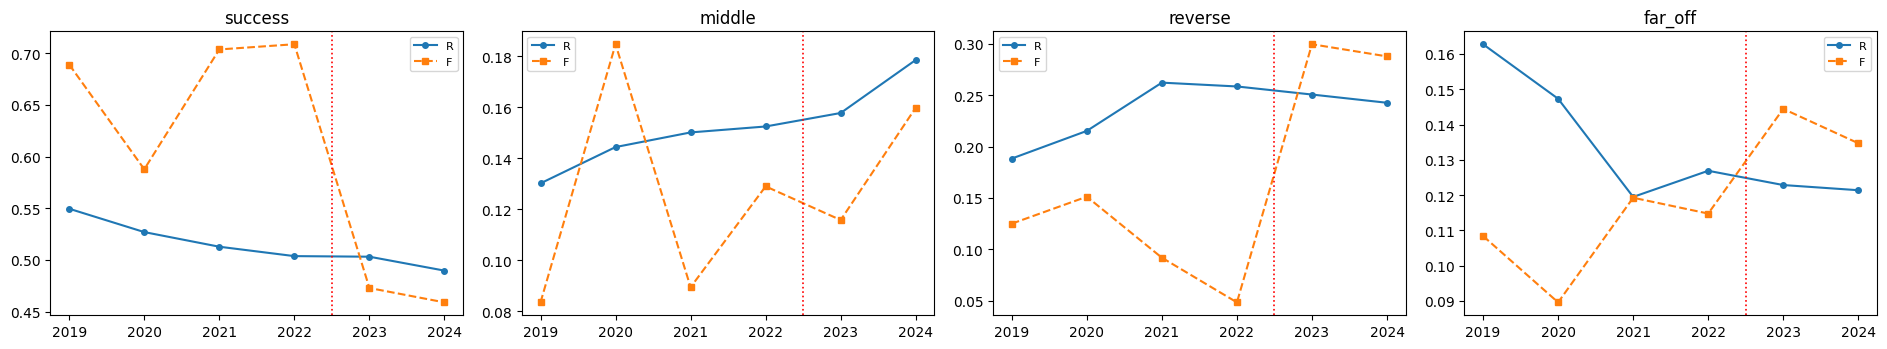

In [8]:
fig, axes = plt.subplots(1, 4, figsize=(19, 3.6))
for ax, c in zip(axes, ["success", "middle", "reverse", "far_off"]):
    p = D.pivot_table(index="season", columns="game_type", values=c, aggfunc="mean")
    for gt, st in [("R", "-o"), ("F", "--s")]:
        if gt in p.columns:
            ax.plot(p.index, p[gt], st, ms=4, label=gt)
    ax.axvline(2022.5, color="red", ls=":", lw=1.2)
    ax.set_title(c); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

In [9]:
# 같은 투수 짝지은 차이를 성분별로 — 실력차가 아니라 측정 변화임을 확정
rows = []
for s, sub in D.groupby("season"):
    piv = sub.pivot_table(index="pitcher_id", columns="game_type",
                          values=["success", "reverse", "middle", "far_off"], aggfunc="mean")
    cnt = sub.pivot_table(index="pitcher_id", columns="game_type", values="success", aggfunc="size")
    if not {"F", "R"}.issubset(cnt.columns):
        continue
    keep = cnt[(cnt["F"] >= 50) & (cnt["R"] >= 50)].index
    piv = piv.loc[piv.index.intersection(keep)].dropna()
    rec = {"season": s, "n_pitchers": len(piv)}
    for c in ["success", "reverse", "middle", "far_off"]:
        rec[f"d_{c}"] = (piv[(c, "F")] - piv[(c, "R")]).mean()
    rows.append(rec)
print(pd.DataFrame(rows).round(4).to_string(index=False))
print("\n-> d_success 붕괴가 d_reverse 붕괴로 설명되면 가설 확정")

 season  n_pitchers  d_success  d_reverse  d_middle  d_far_off
   2019          66     0.1953    -0.1154   -0.0537    -0.0539
   2020          56     0.1263    -0.1007    0.0213    -0.0692
   2021          87     0.2156    -0.1965   -0.0549    -0.0031
   2022          85     0.2442    -0.2397   -0.0157    -0.0291
   2023          77     0.0114     0.0111   -0.0396     0.0207
   2024          83     0.0058     0.0080    0.0075    -0.0047

-> d_success 붕괴가 d_reverse 붕괴로 설명되면 가설 확정


## 4. 오염 제거 — R 전용 누적 제구율 재구성

`asof_pitcher_success_rate` 는 R/F 를 섞어 계산돼 있어, 2군을 많이 던진
팀13 투수에게 +0.035 의 상향 편향이 있었다 (노트북 01 후속 진단).

`control_success` 는 모든 행에 있으므로 차분 없이 바로 재구성할 수 있다.
**strictly prior** 를 지키려면 cumsum 후 자기 자신을 뺀다.

In [10]:
P2 = P.copy()
is_R = (P2["game_type"] == "R").to_numpy().astype(np.int64)
y_all = P2[TARGET].to_numpy().astype(np.int64)

g = P2.groupby("pitcher_id", sort=False)
# 자기 자신 포함 누적 -> 자기 자신 제외 (strictly prior)
P2["_isR"] = is_R
P2["_yR"] = y_all * is_R
cum_nR = P2.groupby("pitcher_id")["_isR"].cumsum() - P2["_isR"]
cum_yR = P2.groupby("pitcher_id")["_yR"].cumsum() - P2["_yR"]

P2["asof_pitcher_success_rate_R"] = np.where(cum_nR > 0, cum_yR / cum_nR, np.nan)
P2["asof_pitcher_n_R"] = cum_nR

# F 전용도 같이
P2["_isF"] = 1 - is_R
P2["_yF"] = y_all * (1 - is_R)
cum_nF = P2.groupby("pitcher_id")["_isF"].cumsum() - P2["_isF"]
cum_yF = P2.groupby("pitcher_id")["_yF"].cumsum() - P2["_yF"]
P2["asof_pitcher_success_rate_F"] = np.where(cum_nF > 0, cum_yF / cum_nF, np.nan)
P2["asof_pitcher_n_F"] = cum_nF
P2.drop(columns=["_isR", "_yR", "_isF", "_yF"], inplace=True)

print(P2[["asof_pitcher_n", "asof_pitcher_n_R", "asof_pitcher_n_F",
          "asof_pitcher_success_rate", "asof_pitcher_success_rate_R"]].describe().round(4))

       asof_pitcher_n  asof_pitcher_n_R  asof_pitcher_n_F  asof_pitcher_success_rate  asof_pitcher_success_rate_R
count    1.475092e+06      1.475092e+06      1.475092e+06               1.474300e+06                 1.432207e+06
mean     2.661323e+03      2.538086e+03      1.232370e+02               5.352000e-01                 5.185000e-01
std      2.690013e+03      2.704541e+03      3.414834e+02               6.180000e-02                 6.250000e-02
min      0.000000e+00      0.000000e+00      0.000000e+00               0.000000e+00                 0.000000e+00
25%      6.840000e+02      5.480000e+02      0.000000e+00               4.991000e-01                 4.833000e-01
50%      1.776000e+03      1.619000e+03      0.000000e+00               5.320000e-01                 5.210000e-01
75%      3.725000e+03      3.581000e+03      9.100000e+01               5.690000e-01                 5.556000e-01
max      1.544900e+04      1.535100e+04      3.986000e+03               1.000000e+00    

In [11]:
# 팀별 최종값 비교 — 편향이 사라졌는가
last = P2.groupby("pitcher_id").tail(1)
tot = P2.groupby("pitcher_id").size().rename("n_total")
team = P2.groupby("pitcher_id")["pitcher_team_id"].agg(lambda s: s.mode().iloc[0]).rename("team")

cmp = (last.set_index("pitcher_id")[["asof_pitcher_success_rate",
                                     "asof_pitcher_success_rate_R"]]
       .join(tot).join(team).query("n_total >= 500"))
out = (cmp.groupby("team")[["asof_pitcher_success_rate", "asof_pitcher_success_rate_R"]]
         .agg(["mean", "size"]).round(4))
out.columns = ["mixed_mean", "n", "R_only_mean", "n2"]
out = out[["n", "mixed_mean", "R_only_mean"]]
out["gap_vs_others"] = (out["R_only_mean"] - out["R_only_mean"].mean()).round(4)
print(out.sort_values("mixed_mean", ascending=False).to_string())

for c in ["asof_pitcher_success_rate", "asof_pitcher_success_rate_R"]:
    t13 = cmp.loc[cmp["team"] == 13, c].mean()
    oth = cmp.loc[cmp["team"] != 13, c].mean()
    print(f"\n{c}\n  팀13 {t13:.4f} / 나머지 {oth:.4f} / 차이 {t13-oth:+.4f}")

       n  mixed_mean  R_only_mean  gap_vs_others
team                                            
13    68      0.5503       0.4790        -0.0223
12    46      0.5253       0.5090         0.0077
18    38      0.5234       0.5187         0.0174
17    51      0.5196       0.5026         0.0013
14    44      0.5179       0.5018         0.0005
15    40      0.5151       0.5105         0.0092
21    49      0.5142       0.4935        -0.0078
20    36      0.5140       0.5004        -0.0009
16    49      0.5078       0.5018         0.0005
19    44      0.5013       0.4955        -0.0058

asof_pitcher_success_rate
  팀13 0.5503 / 나머지 0.5153 / 차이 +0.0349

asof_pitcher_success_rate_R
  팀13 0.4790 / 나머지 0.5034 / 차이 -0.0243


In [18]:
# 수정: R 투구 수 기준으로 필터
last = P2.groupby("pitcher_id").tail(1).set_index("pitcher_id")
team = P2.groupby("pitcher_id")["pitcher_team_id"].agg(lambda s: s.mode().iloc[0]).rename("team")
cmp2 = last[["asof_pitcher_success_rate", "asof_pitcher_success_rate_R", "asof_pitcher_n_R"]].join(team)
cmp2 = cmp2[cmp2["asof_pitcher_n_R"] >= 500]          # ← n_total 이 아니라 n_R

out = cmp2.groupby("team").agg(
    n=("asof_pitcher_n_R", "size"),
    n_R_median=("asof_pitcher_n_R", "median"),
    mixed=("asof_pitcher_success_rate", "mean"),
    r_only=("asof_pitcher_success_rate_R", "mean"),
).round(4)
print(out.sort_values("mixed", ascending=False).to_string())

for c, lab in [("asof_pitcher_success_rate", "혼합"), ("asof_pitcher_success_rate_R", "R전용")]:
    d = cmp2.loc[cmp2.team == 13, c].mean() - cmp2.loc[cmp2.team != 13, c].mean()
    print(f"{lab}: 팀13 − 나머지 = {d:+.4f}")

       n  n_R_median   mixed  r_only
team                                
13    39      2388.0  0.5347  0.4929
18    38      2183.0  0.5234  0.5187
12    41      2631.0  0.5226  0.5153
14    44      1709.0  0.5179  0.5018
15    38      2267.0  0.5170  0.5133
17    46      2433.5  0.5156  0.5035
20    31      2201.0  0.5129  0.5063
21    41      2443.0  0.5103  0.5011
16    48      2013.5  0.5099  0.5043
19    43      2002.0  0.5029  0.4973
혼합: 팀13 − 나머지 = +0.0201
R전용: 팀13 − 나머지 = -0.0136


## 5. 파생 피처 — 시즌 내 누적 투구 수

`asof_pitcher_n` 은 전역 누적이므로, 시즌 시작 시점의 값을 빼면
"이번 시즌 개막 이후 누적 투구 수"가 된다.

**추론 시점 계산법이 다르다.** test(2025) 행에는 2025 시작 시점 값이 없으므로
`asof_pitcher_n − (해당 투수의 train 총 투구 수)` 로 구한다.
train 은 2024 까지 완전하므로 이 차이가 곧 2025 누적치다.
→ 투수별 train 총 투구 수를 lookup 으로 저장해야 한다.

In [12]:
# train 행용
P2["season_to_date_pitches"] = (
    P2["asof_pitcher_n"] - P2.groupby(["pitcher_id", "season"])["asof_pitcher_n"].transform("min")
)
print(P2.groupby("season")["season_to_date_pitches"].describe().round(1))

# 추론용 lookup: 투수별 train 총 투구 수 (= 2025 시작 시점의 asof_pitcher_n)
lookup = (P2.groupby("pitcher_id")["asof_pitcher_n"].max() + 1).rename("n_train_total").reset_index()
lookup.to_parquet(os.path.join(ART_DIR, "pitcher_train_totals.parquet"), index=False)
print(f"\nlookup 저장: {len(lookup)} 투수")
print(lookup.head())
print("\n※ test 에서: season_to_date = asof_pitcher_n - n_train_total")
print("   신규 투수(lookup 없음)는 asof_pitcher_n 자체가 시즌 내 누적치")

           count   mean    std  min    25%    50%     75%     max
season                                                           
2019    237413.0  768.7  682.7  0.0  223.0  571.0  1115.0  3141.0
2020    244087.0  744.0  685.4  0.0  216.0  524.0  1071.0  3524.0
2021    247088.0  712.0  661.5  0.0  203.0  507.0  1007.0  3404.0
2022    247472.0  734.1  669.8  0.0  208.0  527.0  1067.0  3002.0
2023    245525.0  702.6  627.0  0.0  212.0  526.0  1000.0  2987.0
2024    253507.0  687.2  627.5  0.0  208.0  505.0   965.0  3123.0

lookup 저장: 792 투수
   pitcher_id  n_train_total
0       20700            959
1       20938            638
2       21095            263
3       21170             20
4       21178            165

※ test 에서: season_to_date = asof_pitcher_n - n_train_total
   신규 투수(lookup 없음)는 asof_pitcher_n 자체가 시즌 내 누적치


In [14]:
# 타자 쪽도 동일하게 디코딩 (success / middle)
B = train.sort_values(["batter_id", "asof_batter_n"], kind="mergesort").reset_index(drop=True)
bdec = {}
for name, col in {"success": "asof_batter_success_rate", "middle": "asof_batter_middle_rate"}.items():
    raw, cnt, ok, dev = decode_series(B, col, "asof_batter_n", "batter_id")
    bdec[name] = np.where(ok, np.round(raw), np.nan)
    print(f"batter {name:8s} 정수이탈 {dev:.3e}  유효 {int(ok.sum()):,}")

okb = np.isfinite(bdec["success"])
print("\n타자 success 불일치:",
      int((bdec['success'][okb] != B[TARGET].to_numpy()[okb]).sum()))

# 구종 성분 — pitchmix 분모가 asof_pitcher_n 과 같은지 먼저 확인
same_denom = (train["asof_pitcher_pitchmix_n"] == train["asof_pitcher_n"]).mean()
print(f"\npitchmix_n == asof_pitcher_n 비율: {same_denom:.4f}")

batter success  정수이탈 6.920e-03  유효 1,474,262
batter middle   정수이탈 6.892e-03  유효 1,474,262

타자 success 불일치: 0

pitchmix_n == asof_pitcher_n 비율: 1.0000


In [15]:
# 구종군 복원 (분모는 pitchmix_n)
for name, col in {"fastball": "asof_pitcher_fastball_rate",
                  "breaking": "asof_pitcher_breaking_rate",
                  "offspeed": "asof_pitcher_offspeed_rate"}.items():
    raw, cnt, ok, dev = decode_series(P, col, "asof_pitcher_pitchmix_n", "pitcher_id")
    D.loc[:, name] = np.where(ok, np.round(raw), np.nan)[OK]
    print(f"{name:9s} 정수이탈 {dev:.3e}")

D["other_type"] = (1 - D[["fastball", "breaking", "offspeed"]].sum(axis=1)).astype(float)
print("\n구종군 비율:", D[["fastball", "breaking", "offspeed", "other_type"]].mean().round(4).to_dict())
print("\n⚠️ 구종은 규칙 6에 의해 '현재 투구의 실제 구종'을 입력으로 쓸 수 없다.")
print("   strictly prior 집계(과거 구종 이력)로만 사용할 것.")

fastball  정수이탈 7.594e-03
breaking  정수이탈 7.672e-03
offspeed  정수이탈 7.643e-03

구종군 비율: {'fastball': 0.5414, 'breaking': 0.2958, 'offspeed': 0.1627, 'other_type': 0.0}

⚠️ 구종은 규칙 6에 의해 '현재 투구의 실제 구종'을 입력으로 쓸 수 없다.
   strictly prior 집계(과거 구종 이력)로만 사용할 것.


## 6. 저장

복원된 per-pitch 성분을 parquet 으로 저장한다.
노트북 03(피처 엔지니어링)에서 이걸 재료로 쓴다.

In [16]:
save_cols = ["row_id", "pitcher_id", "season", "game_type", "asof_pitcher_n",
             "success", "middle", "reverse", "far_off", "ball", "strike", "inplay",
             "fastball", "breaking", "offspeed"]
D[save_cols].to_parquet(os.path.join(ART_DIR, "decoded_pitch_outcomes.parquet"), index=False)

P2[["row_id", "asof_pitcher_n_R", "asof_pitcher_success_rate_R",
    "asof_pitcher_n_F", "asof_pitcher_success_rate_F",
    "season_to_date_pitches"]].to_parquet(
    os.path.join(ART_DIR, "rebuilt_asof_features.parquet"), index=False)

print("저장 완료:")
for f in sorted(os.listdir(ART_DIR)):
    print(f"  {f}  ({os.path.getsize(os.path.join(ART_DIR, f))/1e6:.1f} MB)")

저장 완료:
  decoded_pitch_outcomes.parquet  (13.3 MB)
  pitcher_train_totals.parquet  (0.0 MB)
  rebuilt_asof_features.parquet  (21.6 MB)


## 7. 요약 — 판정

세 가지 확인 사항의 결론을 한 번에 찍는다.

In [17]:
print("=" * 72)
print("1) 디코딩 정합성")
print(f"   success 차분 불일치: {int((dec['success'][OK] != y[OK]).sum())} 건  -> 0 이어야 함")

print("\n2) 라벨 레짐 단절 (F reverse)")
r = D.pivot_table(index="season", columns="game_type", values="reverse", aggfunc="mean")
for s in r.index:
    fv = r.loc[s, "F"] if "F" in r.columns else np.nan
    rv = r.loc[s, "R"] if "R" in r.columns else np.nan
    print(f"   {s}: F={fv:.5f}  R={rv:.5f}  ratio={fv/rv if rv else np.nan:.3f}")
print("   -> 2022 이전 F ratio 가 0 근처면 '포수 타깃 미기록' 가설 확정")

print("\n3) 오염 제거")
for c, lab in [("asof_pitcher_success_rate", "혼합(원본)"),
               ("asof_pitcher_success_rate_R", "R 전용(재구성)")]:
    t13 = cmp.loc[cmp["team"] == 13, c].mean()
    oth = cmp.loc[cmp["team"] != 13, c].mean()
    print(f"   {lab:16s} 팀13-나머지 = {t13-oth:+.4f}")
print("   -> R 전용에서 차이가 0 근처로 줄면 편향 제거 성공")
print("=" * 72)

1) 디코딩 정합성
   success 차분 불일치: 0 건  -> 0 이어야 함

2) 라벨 레짐 단절 (F reverse)
   2019: F=0.12492  R=0.18836  ratio=0.663
   2020: F=0.15119  R=0.21530  ratio=0.702
   2021: F=0.09175  R=0.26232  ratio=0.350
   2022: F=0.04824  R=0.25859  ratio=0.187
   2023: F=0.29973  R=0.25072  ratio=1.195
   2024: F=0.28789  R=0.24270  ratio=1.186
   -> 2022 이전 F ratio 가 0 근처면 '포수 타깃 미기록' 가설 확정

3) 오염 제거
   혼합(원본)           팀13-나머지 = +0.0349
   R 전용(재구성)        팀13-나머지 = -0.0243
   -> R 전용에서 차이가 0 근처로 줄면 편향 제거 성공
